In [1]:
import os
import shutil
import warnings
warnings.filterwarnings('ignore')  

file_count = sum(len(filenames) for _, _, filenames in os.walk('/kaggle/input'))
print(f"Number of files in the input folder: {file_count}")

folder_to_clear = '/kaggle/working/'
if os.path.exists(folder_to_clear):
    for filename in os.listdir(folder_to_clear):
        file_path = os.path.join(folder_to_clear, filename)
        if os.path.isfile(file_path) or os.path.islink(file_path):
            os.unlink(file_path)
        elif os.path.isdir(file_path):
            shutil.rmtree(file_path)
print("Working folder cleared successfully.")

Number of files in the input folder: 25002
Working folder cleared successfully.


In [2]:
import os
import shutil
from PIL import Image

source_dir = '/kaggle/input/insect-village-synthetic-dataset'
destination_dir = '/content/corrupted_images'  
os.makedirs(destination_dir, exist_ok=True)

corrupted_count = 0
total_files = 0

for root, _, files in os.walk(source_dir):
    for file in files:
        total_files += 1
        file_path = os.path.join(root, file)
        try:
            with Image.open(file_path) as img:
                img.verify() 
        except (IOError, SyntaxError, ValueError) as e:
            shutil.copy(file_path, destination_dir)
            corrupted_count += 1
            print(f" corrupted image: {file_path}")

print(f"\n Total number of files: {total_files}")
print(f"Number of corrupted images copied: {corrupted_count}")

 corrupted image: /kaggle/input/insect-village-synthetic-dataset/ImageClassesCombinedWithCOCOAnnotations/coco_instances.json

 Total number of files: 25002
Number of corrupted images copied: 1


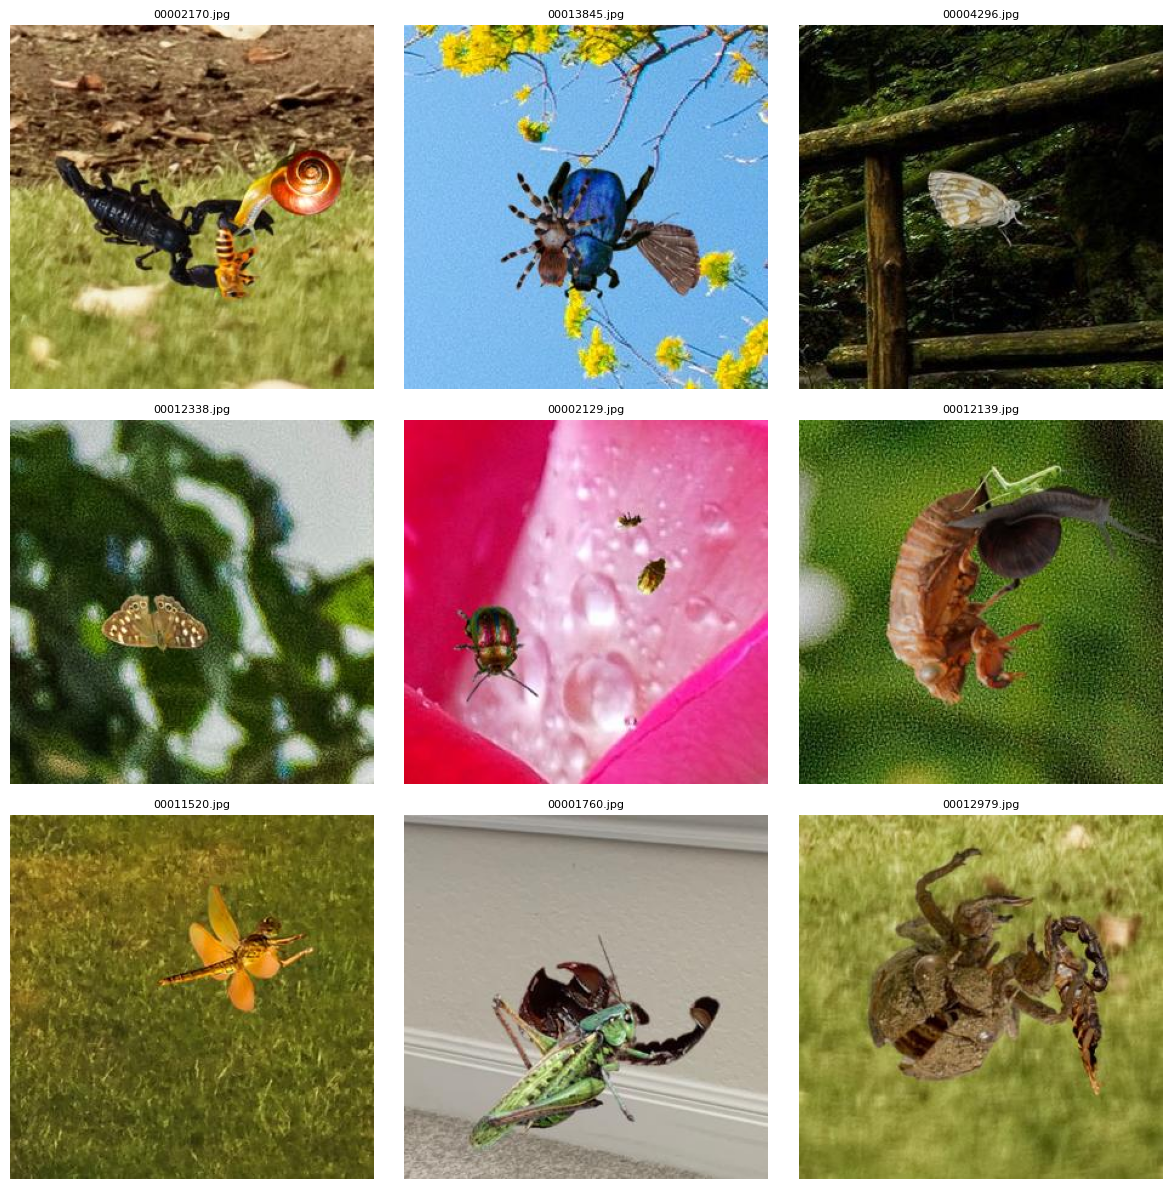

In [3]:
import os
import matplotlib.pyplot as plt
from PIL import Image

image_dir = '/kaggle/input/insect-village-synthetic-dataset/ImageClassesCombinedWithCOCOAnnotations/images_raw'

image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.png', '.jpeg'))][:9]

plt.figure(figsize=(12, 12))
for idx, image_name in enumerate(image_files):
    img_path = os.path.join(image_dir, image_name)
    img = Image.open(img_path)
    plt.subplot(3, 3, idx + 1)
    plt.imshow(img)
    plt.title(image_name, fontsize=8)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [4]:
import json
import os

coco_file_path = '/kaggle/input/insect-village-synthetic-dataset/ImageClassesCombinedWithCOCOAnnotations/coco_instances.json'

with open(coco_file_path, 'r') as f:
    coco_data = json.load(f)

labels_dir = '/content/yolo_labels'
os.makedirs(labels_dir, exist_ok=True)

categories = {cat['id']: cat['name'] for cat in coco_data['categories']}
print("Categories:", categories)

for image in coco_data['images']:
    image_id = image['id']
    image_file_name = image['file_name']
    
    label_file_path = os.path.join(labels_dir, os.path.splitext(image_file_name)[0] + '.txt')
    
    annotations = [ann for ann in coco_data['annotations'] if ann['image_id'] == image_id]
    
    with open(label_file_path, 'w') as label_file:
        for ann in annotations:
            category_id = ann['category_id']
            category_name = categories[category_id]
            
            x, y, width, height = ann['bbox']
            
            x_center = (x + width / 2) / image['width']
            y_center = (y + height / 2) / image['height']
            w = width / image['width']
            h = height / image['height']
            
            label_file.write(f"{category_id - 1} {x_center} {y_center} {w} {h}\n")

print(" COCO file converted to YOLO format successfully.")

Categories: {1: 'grasshoppers', 2: 'butterfly', 3: 'cicada', 4: 'dragonfly', 5: 'spider', 6: 'snail', 7: 'scorpion', 8: 'bees', 9: 'moth', 10: 'beetle'}
 COCO file converted to YOLO format successfully.


In [5]:
import os
import json
import shutil
from PIL import Image
from tqdm import tqdm

json_path = '/kaggle/input/insect-village-synthetic-dataset/ImageClassesCombinedWithCOCOAnnotations/coco_instances.json'
images_dir = '/kaggle/input/insect-village-synthetic-dataset/ImageClassesCombinedWithCOCOAnnotations/images_raw'
output_dir = '/kaggle/working/yolo_dataset'
labels_dir = os.path.join(output_dir, 'labels')
yolo_images_dir = os.path.join(output_dir, 'images')

os.makedirs(labels_dir, exist_ok=True)
os.makedirs(yolo_images_dir, exist_ok=True)

with open(json_path, 'r') as f:
    coco_data = json.load(f)

categories = coco_data['categories']
category_id_map = {}  
category_names = []

for i, cat in enumerate(categories):
    category_id_map[cat['id']] = i
    category_names.append(cat['name'])

print(f" Total classes: {len(category_names)}")
print(f" Class names: {category_names}")

annotations_by_image = {}
for ann in coco_data['annotations']:
    img_id = ann['image_id']
    if img_id not in annotations_by_image:
        annotations_by_image[img_id] = []
    annotations_by_image[img_id].append(ann)

error_count = 0

for img_info in tqdm(coco_data['images'], desc=" Converting"):
    file_name = img_info['file_name']
    image_id = img_info['id']
    width = img_info['width']
    height = img_info['height']

    src_img_path = os.path.join(images_dir, file_name)
    dst_img_path = os.path.join(yolo_images_dir, file_name)

    if not os.path.exists(src_img_path):
        print(f"Missing image file: {file_name}")
        error_count += 1
        continue

    shutil.copy(src_img_path, dst_img_path)

    label_lines = []
    for ann in annotations_by_image.get(image_id, []):
        cat_id = ann['category_id']
        bbox = ann['bbox']  

        x, y, w, h = bbox
        x_center = (x + w / 2) / width
        y_center = (y + h / 2) / height
        w /= width
        h /= height

        yolo_cat_id = category_id_map[cat_id]
        label_lines.append(f"{yolo_cat_id} {x_center:.6f} {y_center:.6f} {w:.6f} {h:.6f}")

    label_file_name = os.path.splitext(file_name)[0] + '.txt'
    label_path = os.path.join(labels_dir, label_file_name)
    with open(label_path, 'w') as f:
        f.write('\n'.join(label_lines))

print(f"\n Conversion completed successfully.")
print(f" Number of files with issues: {error_count}")

 Total classes: 10
 Class names: ['grasshoppers', 'butterfly', 'cicada', 'dragonfly', 'spider', 'snail', 'scorpion', 'bees', 'moth', 'beetle']


 Converting: 100%|██████████| 15000/15000 [00:18<00:00, 812.90it/s]


 Conversion completed successfully.
 Number of files with issues: 0


In [6]:
import os
import random
import shutil

images_dir = '/kaggle/working/yolo_dataset/images'
labels_dir = '/kaggle/working/yolo_dataset/labels'

train_images_dir = os.path.join(images_dir, 'train')
val_images_dir = os.path.join(images_dir, 'val')
train_labels_dir = os.path.join(labels_dir, 'train')
val_labels_dir = os.path.join(labels_dir, 'val')

os.makedirs(train_images_dir, exist_ok=True)
os.makedirs(val_images_dir, exist_ok=True)
os.makedirs(train_labels_dir, exist_ok=True)
os.makedirs(val_labels_dir, exist_ok=True)

image_files = [f for f in os.listdir(images_dir) if f.endswith(('.jpg', '.png', '.jpeg'))]

train_files = random.sample(image_files, int(0.8 * len(image_files)))
val_files = [f for f in image_files if f not in train_files]

for file_name in train_files:
    shutil.copy(os.path.join(images_dir, file_name), os.path.join(train_images_dir, file_name))
    shutil.copy(os.path.join(labels_dir, file_name.replace('.jpg', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt')),
                os.path.join(train_labels_dir, file_name.replace('.jpg', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt')))

for file_name in val_files:
    shutil.copy(os.path.join(images_dir, file_name), os.path.join(val_images_dir, file_name))
    shutil.copy(os.path.join(labels_dir, file_name.replace('.jpg', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt')),
                os.path.join(val_labels_dir, file_name.replace('.jpg', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt')))

print(f" Data split completed successfully! {len(train_files)} images for training and {len(val_files)} images for validation.")

 Data split completed successfully! 12000 images for training and 3000 images for validation.


In [7]:
import os
import yaml

dataset_path = '/kaggle/working/yolo_dataset'

data_config = {
    'path': dataset_path, 
    'train': 'images/train',  
    'val': 'images/val',  
    'nc': 10,  
    'names': [  
        'grasshoppers',  
        'butterfly',     
        'cicada',        
        'dragonfly',     
        'spider',        
        'snail',         
        'scorpion',      
        'bees',          
        'moth',          
        'beetle'         
    ]
}

yaml_file = os.path.join(dataset_path, 'dataset.yaml')

with open(yaml_file, 'w') as file:
    yaml.dump(data_config, file, default_flow_style=False, sort_keys=False)

print(f"The dataset.yaml file has been successfully created at: {yaml_file}")


!pip install ultralytics

The dataset.yaml file has been successfully created at: /kaggle/working/yolo_dataset/dataset.yaml
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 91.5 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.8.93
    Uninstalling nvidia-nvjitlink-cu12-12.8.93:
      Successfully uninstalled nvidia-nvjitlink-cu12-12.8.93
  Attempting uninstall: nvidia-curand-cu12
    F

In [8]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

model.train(data='/kaggle/working/yolo_dataset/dataset.yaml', epochs=170, imgsz=640, batch=16, name="yolov8_ONE_custom")

model.save('/kaggle/working/yolov8_trained_model.pt')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


100%|██████████| 21.5M/21.5M [00:00<00:00, 115MB/s] 


Ultralytics 8.3.126 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=cuda:0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=170, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=yolov8_ONE_custom, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspectiv

100%|██████████| 755k/755k [00:00<00:00, 23.4MB/s]


Overriding model.yaml nc=80 with nc=10

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     29056  ultralytics.nn.modules.block.C2f             [64, 64, 1, True]             
  3                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  4                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  5                  -1  1    295424  ultralytics.nn.modules.conv.Conv             [128, 256, 3, 2]              
  6                  -1  2    788480  ultralytics.nn.modules.block.C2f             [256, 256, 2, True]           
  7                  -1  1   1180672  ultralytic

...

    170/170      4.24G     0.3541     0.1983     0.8473         34        640: 100%|██████████| 750/750 [03:45<00:00,  3.33it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 94/94 [00:23<00:00,  4.01it/s]

                   all       3000       5929      0.987      0.956      0.983      0.863



170 epochs completed in 11.747 hours.
Optimizer stripped from runs/detect/yolov8_ONE_custom/weights/last.pt, 22.5MB
Optimizer stripped from runs/detect/yolov8_ONE_custom/weights/best.pt, 22.5MB

Validating runs/detect/yolov8_ONE_custom/weights/best.pt...
Ultralytics 8.3.126 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 28.5 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 94/94 [00:25<00:00,  3.62it/s]


                   all       3000       5929      0.988      0.956      0.984      0.863
          grasshoppers        558        589      0.988      0.956      0.985       0.81
             butterfly        572        626       0.99       0.96       0.99      0.902
                cicada        554        590      0.984       0.98      0.994       0.93
             dragonfly        556        595      0.975      0.929      0.967      0.834
                spider        570        622      0.988       0.94      0.983      0.843
                 snail        530        572      0.986      0.979      0.994      0.945
              scorpion        544        578       0.99      0.972      0.988      0.896
                  bees        552        596      0.995      0.928      0.968      0.786
                  moth        507        553      0.982      0.964       0.99      0.911
                beetle        571        608      0.998      0.954      0.976      0.778
Speed: 0.2ms preproce

In [11]:
model.save('/kaggle/working/yolov8_trained_model.pt')

In [12]:
val_results = model.val()

metrics = val_results.results_dict

print(f"Precision: {metrics['metrics/precision(B)']:.4f}")
print(f"Recall: {metrics['metrics/recall(B)']:.4f}")
print(f"mAP@0.5: {metrics['metrics/mAP50(B)']:.4f}")
print(f"mAP@0.5:0.95: {metrics['metrics/mAP50-95(B)']:.4f}")

Ultralytics 8.3.126 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 705.2±407.7 MB/s, size: 19.5 KB)


val: Scanning /kaggle/working/yolo_dataset/labels/val.cache... 3000 images, 0 backgrounds, 0 corrupt: 100%|██████████| 3000/3000 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 188/188 [00:26<00:00,  7.15it/s]


                   all       3000       5929      0.987      0.956      0.983      0.863
          grasshoppers        558        589      0.988      0.956      0.985      0.808
             butterfly        572        626       0.99      0.961       0.99      0.901
                cicada        554        590      0.983       0.98      0.994       0.93
             dragonfly        556        595      0.976      0.929      0.967      0.834
                spider        570        622      0.988      0.941      0.982      0.843
                 snail        530        572      0.984      0.979      0.994      0.945
              scorpion        544        578       0.99      0.972      0.988      0.896
                  bees        552        596      0.995      0.928      0.968      0.787
                  moth        507        553      0.982      0.964       0.99      0.912
                beetle        571        608      0.998      0.954      0.976      0.778
Speed: 0.3ms preproce

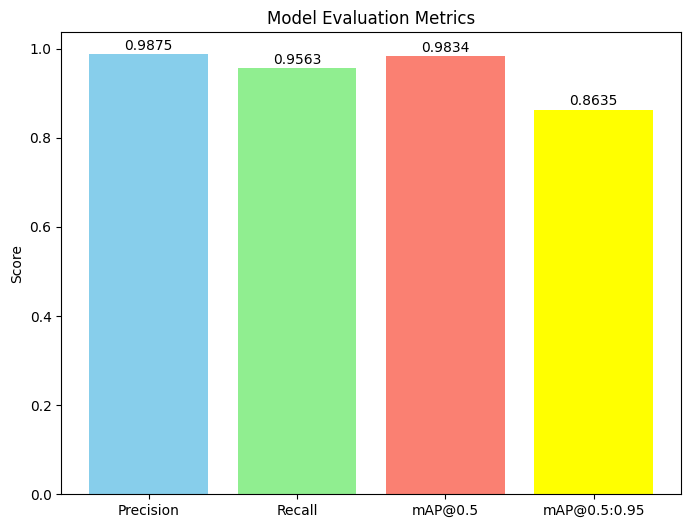

In [13]:
import matplotlib.pyplot as plt

precision = metrics['metrics/precision(B)']
recall = metrics['metrics/recall(B)']
map_50 = metrics['metrics/mAP50(B)']
map_50_95 = metrics['metrics/mAP50-95(B)']

metrics_values = [precision, recall, map_50, map_50_95]
metrics_labels = ['Precision', 'Recall', 'mAP@0.5', 'mAP@0.5:0.95']

plt.figure(figsize=(8, 6))
plt.bar(metrics_labels, metrics_values, color=['skyblue', 'lightgreen', 'salmon', 'yellow'])

plt.title('Model Evaluation Metrics')
plt.ylabel('Score')

for i, value in enumerate(metrics_values):
    plt.text(i, value + 0.01, f'{value:.4f}', ha='center')

plt.show()

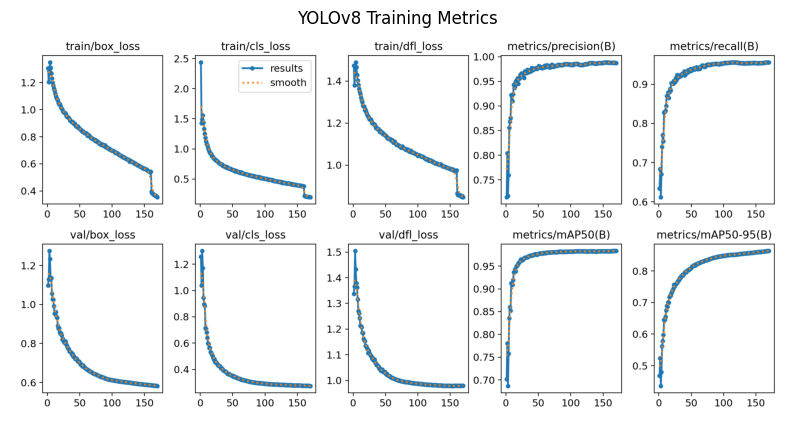

In [14]:
import matplotlib.pyplot as plt
import cv2
import os

metrics_img = "runs/detect/yolov8_ONE_custom/results.png"

if os.path.exists(metrics_img):
    img = cv2.imread(metrics_img)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.axis('off')
    plt.title("YOLOv8 Training Metrics")
    plt.show()
else:
    print(f"Metrics image not found at: {metrics_img}. Make sure training is complete and the name is correct.")

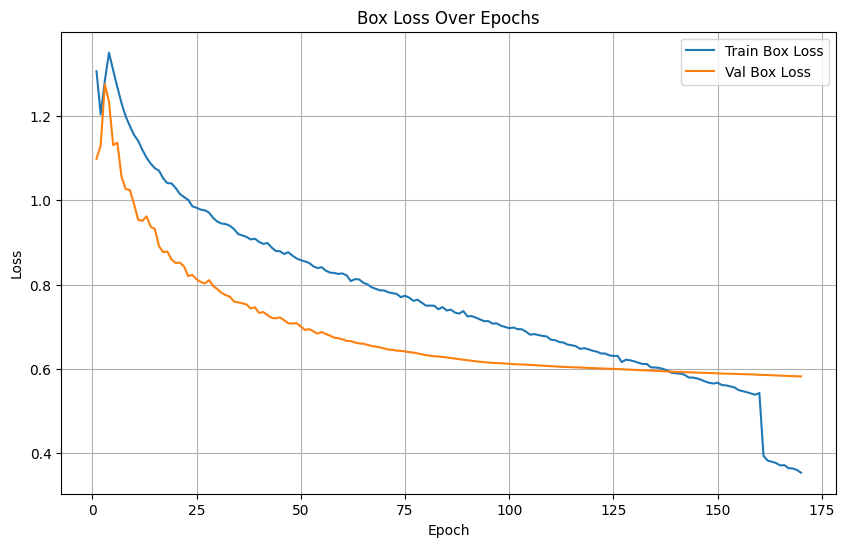

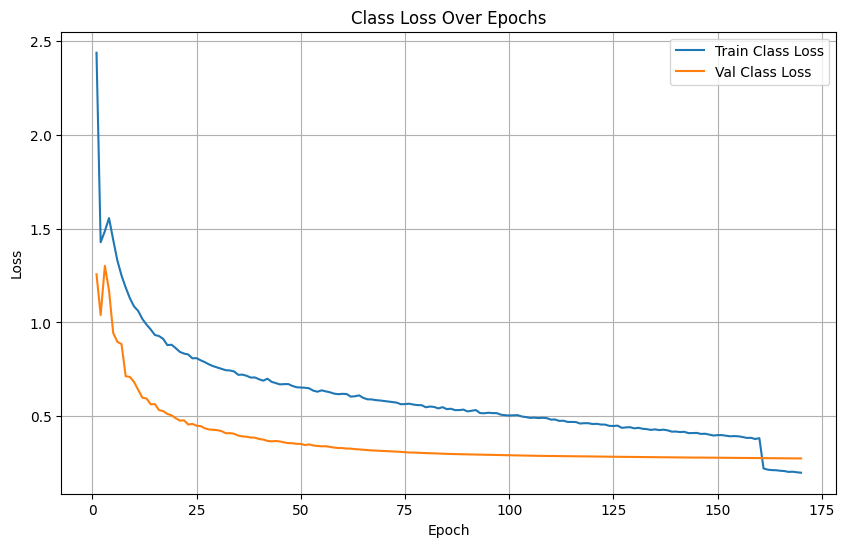

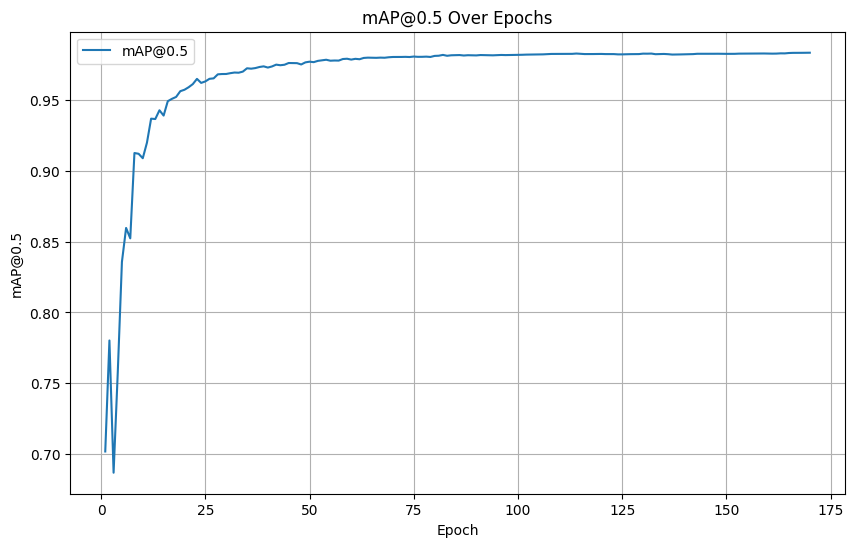

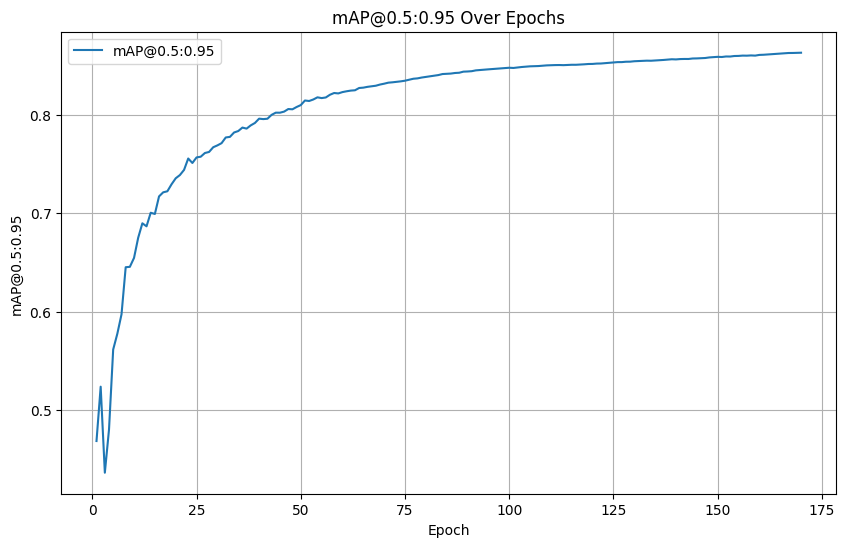

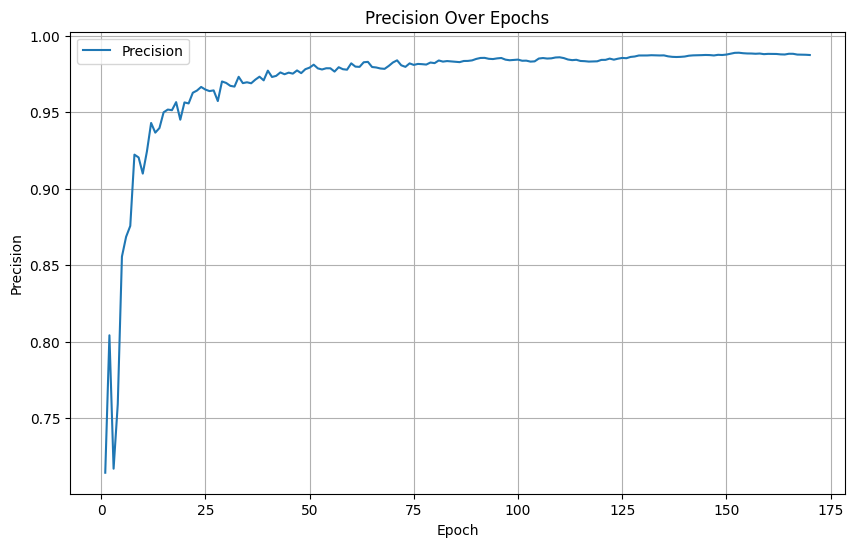

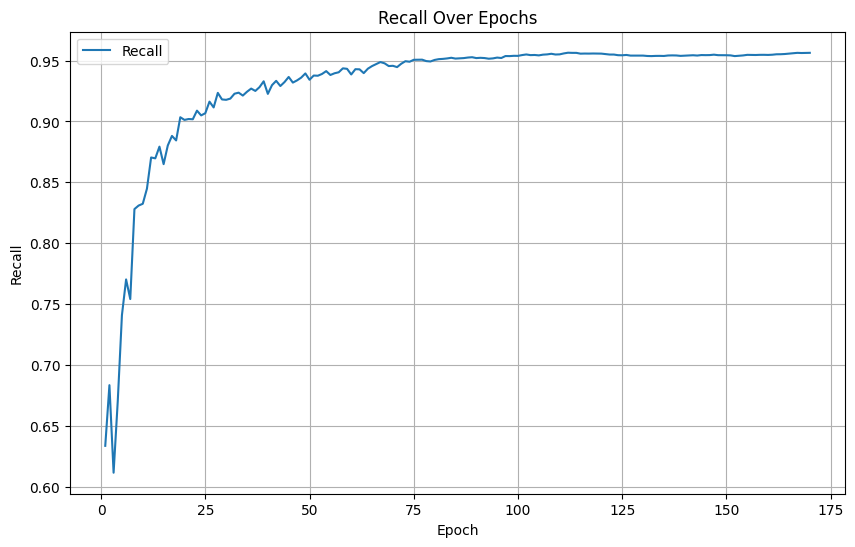

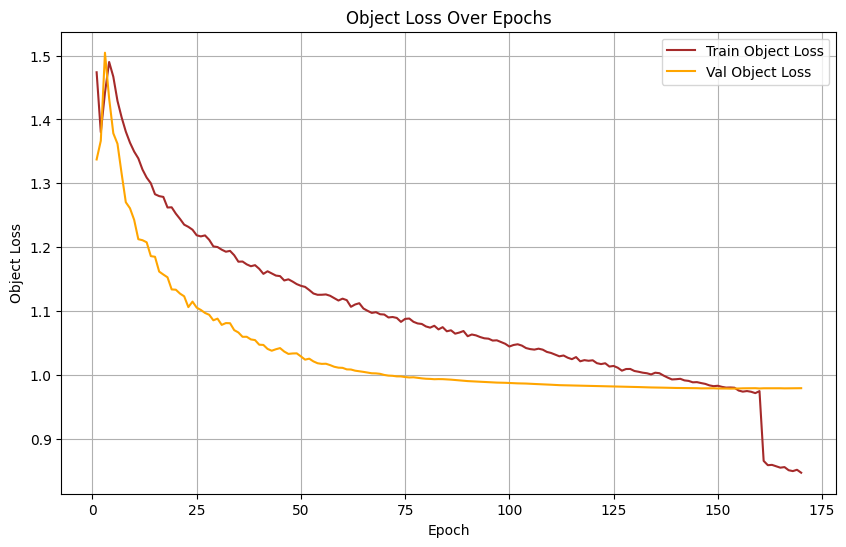

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

metrics_file = '/kaggle/working/runs/detect/yolov8_ONE_custom/results.csv'
metrics = pd.read_csv(metrics_file)

metrics.columns = metrics.columns.str.strip()

plt.figure(figsize=(10, 6))
plt.plot(metrics['epoch'], metrics['train/box_loss'], label='Train Box Loss')
plt.plot(metrics['epoch'], metrics['val/box_loss'], label='Val Box Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Box Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(metrics['epoch'], metrics['train/cls_loss'], label='Train Class Loss')
plt.plot(metrics['epoch'], metrics['val/cls_loss'], label='Val Class Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Class Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(metrics['epoch'], metrics['metrics/mAP50(B)'], label='mAP@0.5')
plt.xlabel('Epoch')
plt.ylabel('mAP@0.5')
plt.title('mAP@0.5 Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(metrics['epoch'], metrics['metrics/mAP50-95(B)'], label='mAP@0.5:0.95')
plt.xlabel('Epoch')
plt.ylabel('mAP@0.5:0.95')
plt.title('mAP@0.5:0.95 Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(metrics['epoch'], metrics['metrics/precision(B)'], label='Precision')
plt.xlabel('Epoch')
plt.ylabel('Precision')
plt.title('Precision Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(metrics['epoch'], metrics['metrics/recall(B)'], label='Recall')
plt.xlabel('Epoch')
plt.ylabel('Recall')
plt.title('Recall Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(metrics['epoch'], metrics['train/dfl_loss'], label='Train Object Loss', color='brown')
plt.plot(metrics['epoch'], metrics['val/dfl_loss'], label='Val Object Loss', color='orange')
plt.xlabel('Epoch')
plt.ylabel('Object Loss')
plt.title('Object Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()